<a href="https://colab.research.google.com/github/DinRazar/data-data/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа. Геомаркетинговое исследование территорий с применением методов машинного обучения**

---

## **Введение**

**Практический кейс:** Сеть аптек, пекарен, салонов красоты или пунктов выдачи заказов выбирает, где открыть новые точки. На лекции мы решили эту задачу для кофеен: оценили, сколько кофеен обычно соответствует окружению участка, нашли участки, где их меньше ожидаемого, и выбрали места с учётом конкурентов. В этой работе вы примените тот же подход к другому объекту и выясните, чем его рынок отличается от рынка кофеен.

**Цель работы:** обосновать выбор мест для новых точек выбранного объекта инфраструктуры с помощью модели ожидаемого числа объектов, пространственной статистики и модели Хаффа.

**Маршрут работы:**

| Часть | Вопрос | Что получаем для следующего шага |
|---|---|---|
| 1. Объект и гипотезы | Кто покупатель и что определяет спрос? | Параметры: цель, территория, свои слои, гипотезы |
| 2. Данные | Достаточно ли данных и все ли признаки содержательны? | Таблица признаков по ячейкам H3 |
| 3. Модель | Сколько объектов обычно соответствует окружению и почему? | Ожидаемое число объектов E, главные факторы |
| 4. Разрыв | Где объектов меньше ожидаемого? | Карта разрыва и кластеры недообеспеченности |
| 5. Выбор мест | Где новая точка привлечёт больше всего покупателей? | Список мест с привлекаемым спросом |
| 6. Записка | Почему именно эти места? | Рекомендация для заказчика |

**Данные:**

*   [OpenStreetMap](https://www.openstreetmap.org) через Overpass API — объекты и пешеходный граф улиц.
*   [Kontur Population](https://data.humdata.org/dataset/kontur-population-russian-federation) — население в ячейках H3 (лицензия CC BY 4.0).

**Что вы научитесь делать:**

*   Переносить геомаркетинговую методику на новый тип объекта и новую территорию.
*   Формулировать гипотезы о факторах спроса и проверять их перестановочной важностью.
*   Выбирать модель по пространственной перекрёстной проверке и читать метрику D².
*   Находить кластеры недообеспеченности с помощью индекса Морана и LISA.
*   Выбирать параметр модели Хаффа и проверять устойчивость рекомендаций.
*   Писать обоснованную рекомендацию по размещению для заказчика.

**Самостоятельные решения.** Вы выбираете объект, территорию, дополнительные слои признаков, размер зоны обслуживания, параметр λ модели Хаффа и число мест, формулируете гипотезы и пишете выводы. Загрузка данных, построение признаков, модели и карты даны готовыми функциями — их устройство разобрано на лекции.

> 📝 **Как выполнять работу.** Выполняйте ячейки по порядку. В ячейках с `# ВАШ КОД` допишите код по заданию над ячейкой: имена переменных из задания используются дальше. Ответы на вопросы впишите в ячейки «**Ответ:** _______________» (двойной щелчок по ячейке → текст → Shift+Enter). Ответ должен опираться на полученные числа и карты. Материалы лекции: [**Геомаркетинговое исследование территорий**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj).

---

## **Часть 0. Настройка окружения**

Установим библиотеки с зафиксированными версиями и импортируем их. GPU не нужен.

In [1]:
%pip install -q osmnx==2.1.1 geopandas==1.2.0 shapely==2.1.2 h3==4.5.0 scikit-learn==1.9.1 esda==2.10.0 libpysal==4.15.0 shap==0.54.1 folium==0.20.0 mapclassify==2.11.0 leafmap==0.63.1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os, time, gzip, shutil, urllib.request  # Файлы, время, архивы
from concurrent.futures import ThreadPoolExecutor  # Параллельная проверка зеркал Overpass
import numpy as np, pandas as pd, geopandas as gpd  # Таблицы и геоданные
import h3, osmnx as ox, networkx as nx, requests, folium  # H3, граф улиц, запросы, карты
import matplotlib.pyplot as plt  # Графики
from shapely.geometry import box, Polygon  # Геометрии
from scipy.spatial.distance import cdist  # Попарные расстояния
from scipy.stats import poisson, spearmanr  # Распределение Пуассона, ранговая корреляция
from sklearn.base import clone  # Копия модели с теми же параметрами
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict  # Перекрёстная проверка
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor  # Ансамбли
from sklearn.linear_model import PoissonRegressor  # Регрессия Пуассона
from sklearn.dummy import DummyRegressor  # Постоянный прогноз
from sklearn.pipeline import make_pipeline  # Цепочка преобразований
from sklearn.preprocessing import FunctionTransformer, StandardScaler  # Логарифм и стандартизация
from sklearn.metrics import d2_tweedie_score  # D² для счётных данных
from libpysal.weights import W  # Матрица соседства
from esda.moran import Moran, Moran_Local  # Индекс Морана и LISA
import shap  # Объяснение прогнозов
import leafmap.leafmap as leafmap  # Карта для выбора территории

ox.settings.use_cache = True  # Повторные запросы графа — из кэша
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = False
SEED = 42  # Воспроизводимость
H3_RES = 9  # Ячейки со стороной около 200 м
MARGIN_M = 800  # Запас вокруг территории при загрузке данных, м
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Ниже — готовые функции из лекции, обобщённые на любой объект. Их не нужно менять; чтобы посмотреть код, разверните ячейку.

In [3]:
#@title Готовые функции: загрузка данных
OVERPASS_SERVERS = [  # Общедоступные зеркала Overpass API
    "https://overpass-api.de/api/interpreter",
    "https://lz4.overpass-api.de/api/interpreter",
    "https://z.overpass-api.de/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
]
PROBE_AREA = "(55.750,37.600,55.760,37.620)"  # Участок центра Москвы с кафе для проверки зеркал
HEADERS = {"User-Agent": "geomarketing-course"}
BASE_LAYERS = {  # Слои признаков из лекции: ключ OSM и значения (None — любое значение)
    "cafes": ("amenity", ["cafe"]),
    "food": ("amenity", ["restaurant", "fast_food", "bar", "pub"]),
    "shops": ("shop", None),
    "services": ("amenity", ["bank", "pharmacy", "post_office"]),
    "offices": ("office", None),
    "education": ("amenity", ["university", "college"]),
    "culture": ("amenity", ["theatre", "cinema", "library", "arts_centre"]),
    "tourism": ("tourism", ["hotel", "hostel", "guest_house", "attraction", "museum"]),
    "fitness": ("leisure", ["fitness_centre"]),
    "stops": ("highway", ["bus_stop"]),
    "metro": ("railway", ["subway_entrance"]),
}


def osm_filter(key, values):
    """Фильтр Overpass для ключа и списка значений (None — любое значение)."""
    return f'nwr["{key}"]' if values is None else f'nwr["{key}"~"^({"|".join(values)})$"]'


def layer_mask(points, key, values):
    """Маска объектов слоя в таблице точек."""
    if key not in points:
        return pd.Series(False, index=points.index)
    return points[key].notna() if values is None else points[key].isin(values)


def probe_server(url, date=None):
    """Результат пробного запроса к зеркалу: ('ok', секунды, дата данных), ('empty', …) или ('fail', …)."""
    header = "[out:json][timeout:25]" + (f'[date:"{date}T00:00:00Z"]' if date else "")
    start = time.time()
    try:
        response = requests.post(url, data={"data": header + f';nwr["amenity"="cafe"]{PROBE_AREA};out ids;'},
                                 timeout=(5, 60), headers=HEADERS)
        answer = response.json()
    except (requests.RequestException, ValueError):
        return "fail", None, None
    if response.status_code != 200:
        return "fail", None, None
    if not answer.get("elements"):
        return "empty", None, None
    return "ok", time.time() - start, answer["osm3s"]["timestamp_osm_base"][:10]


def rank_servers(date=None):
    """Очередь зеркал: ответившие — по скорости, затем со старыми данными, затем не ответившие на пробу."""
    with ThreadPoolExecutor(len(OVERPASS_SERVERS)) as pool:
        results = list(pool.map(probe_server, OVERPASS_SERVERS, [date] * len(OVERPASS_SERVERS)))
    week_ago = (pd.Timestamp.now() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    rows = []
    for order, (url, (status, seconds, day)) in enumerate(zip(OVERPASS_SERVERS, results)):
        if status == "empty":
            continue
        group = 0 if status == "ok" and day >= week_ago else 1 if status == "ok" else 2
        rows.append({"Зеркало": url.split("/")[2], "Ответ, с": round(seconds, 1) if seconds else "—",
                     "Данные на": day or "нет ответа", "group": group, "order": seconds or order, "url": url})
    table = pd.DataFrame(rows).sort_values(["group", "order"])
    print("Очередь зеркал Overpass:")
    print(table[["Зеркало", "Ответ, с", "Данные на"]].to_string(index=False))
    return table["url"].tolist()


def load_osm_points(bounds, layers, date=None):
    """Загружает объекты всех слоёв layers ({имя: (ключ, значения)}) одним запросом; объекты — точки."""
    west, south, east, north = bounds
    area = f"({south},{west},{north},{east})"
    header = "[out:json][timeout:600]" + (f'[date:"{date}T00:00:00Z"]' if date else "")
    query = header + ";(" + "".join(osm_filter(k, v) + area + ";" for k, v in layers.values()) + ");out tags center;"
    keys = sorted({k for k, v in layers.values()} | {"name"})
    for attempt in range(3):
        for url in rank_servers(date):
            try:
                response = requests.post(url, data={"data": query}, timeout=(20, 660), headers=HEADERS)
                elements = response.json()["elements"] if response.status_code == 200 else []
                if elements:
                    rows = [{"osm_id": f"{e['type']}/{e['id']}",
                             "lat": e.get("lat", e.get("center", {}).get("lat")),
                             "lon": e.get("lon", e.get("center", {}).get("lon")),
                             **{k: e.get("tags", {}).get(k) for k in keys}} for e in elements]
                    table = pd.DataFrame(rows).dropna(subset=["lat", "lon"])
                    return gpd.GeoDataFrame(table, geometry=gpd.points_from_xy(table.lon, table.lat),
                                            crs="EPSG:4326").set_index("osm_id")
                print(f"  {url.split('/')[2]}: код {response.status_code}, объектов {len(elements)}; пробуем другой сервер...")
            except (requests.RequestException, ValueError) as error:
                print(f"  {url.split('/')[2]}: {type(error).__name__}, пробуем другой сервер...")
            time.sleep(15)
    raise RuntimeError("Серверы Overpass не ответили. Повторите ячейку через несколько минут.")


def load_walk_graph(bounds):
    """Пешеходный граф osmnx, начиная с самого быстрого зеркала."""
    for attempt in range(2):
        for url in rank_servers():
            ox.settings.overpass_url = url.rsplit("/", 1)[0]
            try:
                return ox.graph_from_bbox(bounds, network_type="walk")
            except Exception as error:
                print(f"  {url.split('/')[2]}: {type(error).__name__}, пробуем другой сервер...")
                time.sleep(15)
    raise RuntimeError("Граф не загружен. Повторите ячейку через несколько минут.")


POPULATION_URL = "https://geodata-eu-central-1-kontur-public.s3.amazonaws.com/kontur_datasets/kontur_population_RU_20231101.gpkg.gz"


def load_population(bounds, url=POPULATION_URL):
    """Население Kontur (ячейки H3 разрешения 8) в границах bounds."""
    archive = os.path.join(DATA_DIR, url.split("/")[-1]); path = archive[:-3]
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, archive)
        with gzip.open(archive, "rb") as src, open(path, "wb") as dst:
            shutil.copyfileobj(src, dst)
        os.remove(archive)
    bounds_3857 = gpd.GeoSeries([box(*bounds)], crs="EPSG:4326").to_crs("EPSG:3857").total_bounds
    return gpd.read_file(path, bbox=tuple(bounds_3857))

In [4]:
#@title Готовые функции: сетка H3 и признаки
def make_cells(polygon, roi, res):
    """Ячейки H3, покрывающие polygon; in_roi — центр ячейки внутри прямоугольника roi."""
    ids = sorted(h3.geo_to_cells(polygon.__geo_interface__, res))
    shapes = [Polygon([(round(lon, 6), round(lat, 6)) for lat, lon in h3.cell_to_boundary(c)]) for c in ids]
    grid = gpd.GeoDataFrame(index=pd.Index(ids, name="h3"), geometry=shapes, crs="EPSG:4326")
    centers = np.array([h3.cell_to_latlng(c) for c in ids])
    grid["lat"], grid["lon"] = centers[:, 0], centers[:, 1]
    grid["in_roi"] = grid.lon.between(roi[0], roi[2]) & grid.lat.between(roi[1], roi[3])
    return grid


def to_cells(points, res):
    """Ячейка H3 для каждой точки."""
    return pd.Series([h3.latlng_to_cell(y, x, res) for x, y in zip(points.geometry.x, points.geometry.y)], index=points.index)


def population_to_cells(population, grid, res):
    """Население ячеек разрешения 8 поровну делится между дочерними ячейками."""
    values = {}
    for parent, people in zip(population["h3"], population["population"]):
        children = h3.cell_to_children(parent, res)
        for child in children:
            values[child] = people / len(children)
    return pd.Series(values).reindex(grid.index).fillna(0)


def street_features(graph, grid, res):
    """Длина пешеходных путей (км) и число перекрёстков в ячейках."""
    nodes, edges = ox.graph_to_gdfs(graph)
    middle = edges.geometry.interpolate(0.5, normalized=True)
    edge_cell = pd.Series([h3.latlng_to_cell(y, x, res) for x, y in zip(middle.x, middle.y)], index=edges.index)
    crossings = nodes[nodes["street_count"] >= 3]
    return pd.DataFrame({
        "walk_km": edges["length"].groupby(edge_cell).sum().reindex(grid.index, fill_value=0) / 2 / 1000,
        "crossings": pd.Series([h3.latlng_to_cell(y, x, res) for x, y in zip(crossings.x, crossings.y)])
                       .value_counts().reindex(grid.index, fill_value=0),
    })


def metro_walk_distance(graph, grid, metro):
    """Пешеходное расстояние по графу до ближайшего входа в метро, м (если метро нет — 5000)."""
    if len(metro) == 0:
        return pd.Series(5000.0, index=grid.index)
    sources = set(ox.distance.nearest_nodes(graph, metro.geometry.x.values, metro.geometry.y.values))
    distance = nx.multi_source_dijkstra_path_length(graph.to_undirected(), sources, weight="length")
    cell_nodes = ox.distance.nearest_nodes(graph, grid.lon.values, grid.lat.values)
    return pd.Series([distance.get(node, np.nan) for node in cell_nodes], index=grid.index).fillna(5000.0)


def disk_sum(values, k):
    """Сумма значения по ячейке и её соседям до k-го кольца."""
    position = {c: i for i, c in enumerate(values.index)}
    v = values.to_numpy(dtype=float)
    return pd.Series([sum(v[position[n]] for n in h3.grid_disk(c, k) if n in position) for c in values.index], index=values.index)


def build_features(grid, points, target, extra_layers, population, graph, res):
    """Признаки ячеек и число объектов цели. Объекты цели исключаются из всех слоёв признаков."""
    is_target = layer_mask(points, *target)
    other = points[~is_target]  # Без объектов цели — нет утечки
    layers = {name: spec for name, spec in {**BASE_LAYERS, **extra_layers}.items() if name != "metro"}
    cell_of = to_cells(other, res)
    table = pd.DataFrame({name: cell_of[layer_mask(other, *spec)].value_counts().reindex(grid.index, fill_value=0)
                          for name, spec in layers.items()})
    table["population"] = population_to_cells(population, grid, res)
    table = table.join(street_features(graph, grid, res))
    base = list(table.columns)
    for name in base:
        table[f"{name}_r1"] = disk_sum(table[name], 1)
        table[f"{name}_r2"] = disk_sum(table[name], 2)
    table["metro_walk_m"] = metro_walk_distance(graph, grid, other[layer_mask(other, *BASE_LAYERS["metro"])])
    table["target"] = to_cells(points[is_target], res).value_counts().reindex(grid.index, fill_value=0)
    return table, base + ["metro_walk_m"]

In [5]:
#@title Готовые функции: модели, разрыв, модель Хаффа
def compare_models(X, y, groups, seed=42):
    """D² и корреляция Спирмена четырёх моделей при случайной и пространственной проверке."""
    models = {
        "Постоянный прогноз": DummyRegressor(),
        "Регрессия Пуассона": make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=2000)),
        "Случайный лес": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=seed, n_jobs=-1),
        "Градиентный бустинг": HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, random_state=seed),
    }
    rows = []
    for name, model in models.items():
        for cv_name, cv in [("случайная", KFold(5, shuffle=True, random_state=seed)), ("пространственная", GroupKFold(5))]:
            pred = np.clip(cross_val_predict(model, X, y, cv=cv, groups=groups), 1e-6, None)
            rows.append({"Модель": name, "Проверка": cv_name, "D²": d2_tweedie_score(y, pred, power=1),
                         "Спирмен": spearmanr(y, pred).statistic})
    table = pd.DataFrame(rows).pivot(index="Модель", columns="Проверка", values=["D²", "Спирмен"]).round(3)
    return table.sort_values(("D²", "пространственная"), ascending=False), models


def factor_importance(model, X, y, groups, columns, factors, seed=42):
    """Падение D² при перемешивании всех признаков фактора (ячейка, _r1, _r2) на тестовых частях."""
    rng = np.random.default_rng(seed)
    cols = {f: [i for i, c in enumerate(columns) if c == f or c.startswith(f + "_r")] for f in factors}
    drops = {f: [] for f in factors}
    for train, test in GroupKFold(5).split(X, y, groups):
        fitted = clone(model).fit(X[train], y[train])
        base = d2_tweedie_score(y[test], np.clip(fitted.predict(X[test]), 1e-6, None), power=1)
        for f, idx in cols.items():
            X_perm = X[test].copy()
            X_perm[:, idx] = X_perm[rng.permutation(len(test))][:, idx]
            drops[f].append(base - d2_tweedie_score(y[test], np.clip(fitted.predict(X_perm), 1e-6, None), power=1))
    return pd.Series({f: np.mean(v) for f, v in drops.items()}).sort_values(ascending=False)


def gap_table(data, k):
    """Ожидаемое и фактическое число объектов в окрестности k, разрыв и вероятность Пуассона."""
    out = pd.DataFrame(index=data.index)
    out["E_r"] = disk_sum(data["E"], k)
    out["A_r"] = disk_sum(data["target"], k)
    out["gap"] = out.E_r - out.A_r
    out["p_low"] = poisson.cdf(out.A_r, out.E_r)
    return out


def moran_and_lisa(data, seed=42):
    """Индекс Морана для числа объектов и остатков модели, типы LISA для разрыва в ячейке."""
    position = set(data.index)
    neighbours = {c: [n for n in h3.grid_ring(c, 1) if n in position] for c in data.index}
    weights = W(neighbours, id_order=list(data.index), silence_warnings=True)
    weights.transform = "r"
    moran_y = Moran(data["target"].to_numpy(dtype=float), weights, permutations=999)
    moran_res = Moran((data["target"] - data["E"]).to_numpy(), weights, permutations=999)
    print(f"Индекс Морана: число объектов I = {moran_y.I:.3f} (p = {moran_y.p_sim:.3f}), "
          f"остатки модели I = {moran_res.I:.3f} (p = {moran_res.p_sim:.3f})")
    lisa = Moran_Local((data["E"] - data["target"]).to_numpy(), weights, permutations=999, seed=seed)
    names = {1: "HH: кластер недообеспеченности", 2: "LH", 3: "LL: кластер насыщения", 4: "HL"}
    return pd.Series([names[q] if p < 0.05 else "незначимо" for q, p in zip(lisa.q, lisa.p_sim)], index=data.index)


def metric_xy(points, crs):
    """Координаты точек в метрах."""
    geometry = points.to_crs(crs).geometry
    return np.c_[geometry.x, geometry.y]


def huff_supply(cell_xy, shop_xy, lam, d_min=100):
    """Знаменатель модели Хаффа: сумма d^-λ по всем существующим объектам."""
    total = np.zeros(len(cell_xy))
    for start in range(0, len(shop_xy), 500):
        total += (np.maximum(cdist(cell_xy, shop_xy[start:start + 500]), d_min) ** -lam).sum(axis=1)
    return total


def huff_existing_capture(shop_xy, cell_xy, demand, lam, d_min=100):
    """Привлекаемый спрос каждого существующего объекта."""
    supply = huff_supply(cell_xy, shop_xy, lam, d_min)
    w = np.maximum(cdist(shop_xy, cell_xy), d_min) ** -lam
    return (demand[None, :] * w / supply[None, :]).sum(axis=1)


def huff_greedy(cand_xy, cell_xy, demand, shop_xy, n, lam, d_min=100):
    """Жадный выбор n мест с учётом конкурентов и уже выбранных мест."""
    supply = huff_supply(cell_xy, shop_xy, lam, d_min)
    w = np.maximum(cdist(cand_xy, cell_xy), d_min) ** -lam
    picks, gains = [], []
    for step in range(n):
        gain = (demand[None, :] * w / (w + supply[None, :])).sum(axis=1)
        gain[picks] = -np.inf
        best = int(np.argmax(gain)); picks.append(best); gains.append(gain[best])
        supply = supply + w[best]
    return picks, gains


def nearest_distances(xy):
    """Расстояние от каждой точки до ближайшей другой точки набора, м."""
    d = cdist(xy, xy); np.fill_diagonal(d, np.inf)
    return d.min(axis=1)

---

## **Часть 1. Объект, территория и гипотезы**

### **1.1. Выбор объекта**

В таблице — объекты, для которых методика проверена на центре Москвы: указано число объектов в OpenStreetMap и доля объяснённого отклонения D² модели при пространственной проверке. Чем больше объектов и выше D², тем надёжнее результат.

| № | Объект | Теги OSM (`TARGET`) | Кто покупатель, гипотеза о спросе | Радиус обслуживания | Центр Москвы: объектов / D² |
|---|---|---|---|---|---|
| 1 | Аптеки | `("amenity", ["pharmacy"])` | Жители, пожилые, рядом поликлиники | Короткий, 5 мин | 1179 / 0,47 |
| 2 | Фитнес-клубы | `("leisure", ["fitness_centre"])` | Жители и офисные работники | Длинный, 10–15 мин | 253 / 0,11 ⚠ |
| 3 | Ветклиники | `("amenity", ["veterinary"])` | Жители (владельцы животных), парки | Длинный | 96 / < 0 ⚠ |
| 4 | Пекарни | `("shop", ["bakery"])` | Жители, транспорт, утро | Короткий | 308 / 0,24 |
| 5 | Салоны красоты и парикмахерские | `("shop", ["hairdresser", "beauty"])` | Жители, торговые улицы | Средний | 2383 / 0,62 |
| 6 | Продуктовые у дома | `("shop", ["convenience"])` | Жители, вечерние маршруты от метро | Очень короткий | 1109 / 0,35 |
| 7 | Супермаркеты | `("shop", ["supermarket"])` | Жители, крупные покупки | Средний | 722 / 0,31 |
| 8 | Пункты выдачи заказов | `("shop", ["outpost"])` | Жители, маршрут от метро до дома | Короткий | 1595 / 0,38 |
| 9 | Цветочные магазины | `("shop", ["florist"])` | Прохожие, метро, торговые улицы | Короткий | 773 / 0,46 |
| 10 | Стоматологии | `("amenity", ["dentist"])` | Жители и работающие рядом | Средний | 696 / 0,36 |
| 11 | Фастфуд | `("amenity", ["fast_food"])` | Прохожие, транспорт, студенты | Короткий | 1763 / 0,55 |
| 12 | Банкоматы | `("amenity", ["atm"])` | Прохожие, торговые точки | Очень короткий | 829 / 0,38 |
| 13 | Химчистки и прачечные | `("shop", ["dry_cleaning", "laundry"])` | Жители, офисы | Средний | 273 / 0,17 |
| 14 | Салоны связи и ремонт телефонов | `("shop", ["mobile_phone"])` | Прохожие, метро, торговые улицы | Короткий | 271 / 0,47 |
| 15 | Медицинские лаборатории | `("healthcare", ["laboratory"])` | Жители, рядом поликлиники | Средний | 228 / 0,27 |

⚠ — в центре Москвы мало объектов или модель слабая: для них берите территорию крупнее (весь город).

**Можно выбрать и любой свой объект инфраструктуры, которого нет в таблице** — например, зоомагазины (`("shop", ["pet"])`), книжные магазины, хостелы, автомойки. Найдите его тег на [OSM Wiki](https://wiki.openstreetmap.org/wiki/RU:Map_features) и проверьте в части 2, что объектов на вашей территории хотя бы несколько сотен.

> 📚 **Подсказка:** [**Лекция, 1.7. Целевой слой и слои признаков**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=90199521); [**OSM Wiki: теги объектов**](https://wiki.openstreetmap.org/wiki/RU:Map_features).

**1. Задайте название объекта `OBJECT_NAME` и его тег `TARGET` — пару «ключ OSM, список значений».**

In [6]:
OBJECT_NAME = "аптеки"
TARGET = ("amenity", ["pharmacy"])

### **1.2. Выбор территории**

Территория не должна совпадать с той, что была на лекции. Подойдёт другой район Москвы или другой город России: данные о населении Kontur есть по всей стране. Удобный размер — от 5 × 5 до 15 × 15 км: на меньшей территории мало данных для модели, на большей долго загружается граф улиц.

> 📚 **Подсказка:** [**Лекция, 1.4. Выбор ROI**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=72ad25be); [**1.5. Метрическая система координат**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=7f033eb4).

In [9]:
m = leafmap.Map(center=[59.93, 30.33], zoom=11, basemap="Esri.WorldImagery")  # Нарисуйте прямоугольник
m

Map(center=[59.93, 30.33], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_o…

**2. Задайте `BBOX` — границы территории [запад, юг, восток, север]: возьмите их из нарисованного прямоугольника (`m.user_roi_bounds()`) или впишите вручную.**

In [10]:
BBOX = [43.33, 56.21, 43.58, 56.30]

In [11]:
roi_series = gpd.GeoSeries([box(*BBOX)], crs="EPSG:4326")
CRS_METRIC = roi_series.estimate_utm_crs()  # Метрическая проекция UTM для территории
ext_polygon = roi_series.to_crs(CRS_METRIC).buffer(MARGIN_M, join_style=2).to_crs("EPSG:4326").iloc[0]  # С запасом
ext_bounds = ext_polygon.bounds
area_km2 = roi_series.to_crs(CRS_METRIC).area.iloc[0] / 1e6
print(f"Территория: {area_km2:.0f} км², проекция {CRS_METRIC.name}")

Территория: 155 км², проекция WGS 84 / UTM zone 38N


### **1.3. Свои слои признаков**

В лекции признаки отражали спрос на кофе: общепит, магазины, офисы, транспорт. Для вашего объекта может быть важно другое: для аптек — поликлиники, для ветклиник — парки, для пунктов выдачи — жилые комплексы. Слои лекции уже заданы в `BASE_LAYERS`; добавьте к ним 1–2 своих.

<details>
<summary><b>Пример для ветклиник</b></summary>

```python
EXTRA_LAYERS = {
    "parks": ("leisure", ["park", "dog_park"]),  # Парки — прогулки с собаками
    "pet_shops": ("shop", ["pet"]),  # Зоомагазины — владельцы животных рядом
}
```

</details>

> 📚 **Подсказка:** [**Лекция, 1.6. Загрузка объектов OpenStreetMap**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=b401a81c).

**3. Задайте словарь `EXTRA_LAYERS` из 1–2 слоёв: `{"имя": (ключ OSM, [значения])}`.**

In [12]:
EXTRA_LAYERS = {
    "medical": ("amenity", ["clinic", "hospital", "doctors"]),
    "social": ("amenity", ["social_facility", "nursing_home"]),
}

### **1.4. Гипотезы**

Прежде чем считать, запишите, какие факторы, по-вашему, определяют число объектов. Проверять гипотезы вы будете в части 3.

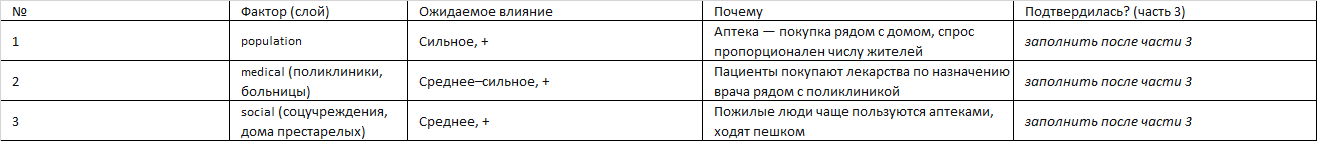

<details>
<summary><b>Пример строки</b></summary>

```python
| № | Фактор (слой) | Ожидаемое влияние | Почему | Подтвердилась? (часть 3) |
|---|---|---|---|---|
| 1 | population | Сильное, + | Аптека — покупка рядом с домом | ... |
```

</details>

**Вопрос 1.1.** Кто основной покупатель вашего объекта и откуда он приходит: из дома, с работы, по пути? Какие слои признаков из этого следуют?

**Ответ:** Основной покупатель аптек в Дзержинске — местные жители, особенно пожилые люди и люди с хроническими заболеваниями, а также пациенты поликлиник и больниц. Большинство приходит из дома (аптека у дома) или по пути от врача. Поэтому ключевые слои признаков: население (population), медицинские учреждения (medical), социальные учреждения (social). Дополнительно можно учитывать остановки общественного транспорта, но для аптек они менее важны, чем для кофеен.

**Вопрос 1.2.** Какую окрестность — k = 1 (около 5 минут пешком) или k = 2 (около 10 минут) — вы считаете зоной обслуживания и почему? Это значение понадобится в части 4.

**Ответ:** Выбираю k = 1 (окрестность около 5 минут пешком, примерно 400–500 м). Аптека — товар повседневного спроса: покупатель, как правило, идёт в ближайшую точку, а не едет через город. Зона обслуживания в одно кольцо H3 (k=1) лучше отражает реальное поведение, чем k=2 (10 минут), хотя для редких и специализированных аптек можно было бы взять

**Вопрос 1.3.** Чем, по-вашему, рынок вашего объекта отличается от рынка кофеен? Зафиксируйте ожидание до расчётов.

**Ответ:** Ожидаю, что рынок аптек отличается от рынка кофеен: для кофеен в лекции главными были общепит и магазины (проходимость, атмосфера улицы), а население почти не влияло. Для аптек, наоборот, население должно быть одним из главных факторов, а близость к поликлиникам и социальным учреждениям — важнее, чем плотность кафе и магазинов. Конкуренция между аптеками может быть менее «атмосферной» и более ценовой/логистической.

---

## **Часть 2. Данные**

### **2.1. Загрузка**

Функция `load_osm_points` загружает все слои одним запросом и сама выбирает самое быстрое зеркало Overpass. Загрузка занимает от нескольких секунд до нескольких минут, граф улиц — несколько минут.

> 📚 **Подсказка:** [**Лекция, 1.6**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=b401a81c); [**1.8. Пешеходный граф**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=6468bd66); [**1.9. Население Kontur**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=b799f508).

**4. Загрузите объекты (`points`) по слоям `{**BASE_LAYERS, "target": TARGET, **EXTRA_LAYERS}`, пешеходный граф (`graph`) и население (`population`) в границах `ext_bounds`.**

In [13]:
points = load_osm_points(ext_bounds, {**BASE_LAYERS, "target": TARGET, **EXTRA_LAYERS})
graph = load_walk_graph(ext_bounds)
population = load_population(ext_bounds)

Очередь зеркал Overpass:
                Зеркало Ответ, с  Данные на
           maps.mail.ru     17.2 2026-11-15
      z.overpass-api.de     31.5 2026-11-15
        overpass-api.de        — нет ответа
    lz4.overpass-api.de        — нет ответа
overpass.private.coffee        — нет ответа
  overpass.kumi.systems        — нет ответа
  maps.mail.ru: код 504, объектов 0; пробуем другой сервер...
  z.overpass-api.de: код 502, объектов 0; пробуем другой сервер...
Очередь зеркал Overpass:
                Зеркало Ответ, с  Данные на
    lz4.overpass-api.de     26.8 2026-11-15
        overpass-api.de        — нет ответа
      z.overpass-api.de        — нет ответа
           maps.mail.ru        — нет ответа
overpass.private.coffee        — нет ответа
  overpass.kumi.systems        — нет ответа


### **2.2. Сетка H3 и признаки**

> 📚 **Подсказка:** [**Лекция, 2.2. Создание сетки**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=ab0fc2c6); [**2.5. Признаки окрестности**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=aacefe50).

**5. Создайте сетку `grid = make_cells(ext_polygon, BBOX, H3_RES)` и таблицу признаков `features, FACTORS = build_features(...)`. Объекты цели функция сама исключает из слоёв признаков.**

In [14]:
grid = make_cells(ext_polygon, BBOX, H3_RES)
features, FACTORS = build_features(grid, points, TARGET, EXTRA_LAYERS, population, graph, H3_RES)

### **2.3. Проверка признаков**

> 📚 **Подсказка:** [**Лекция, 2.6. Проверка признаков**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=4f5c04e0).

**6. Для ячеек территории (`grid.in_roi`) постройте таблицу `check`: для каждого фактора из `FACTORS` и для `target` — доля ячеек со значением больше нуля, медиана и максимум.**

In [15]:
roi_features = features[grid.in_roi]
check = pd.DataFrame({
    "Доля ячеек > 0": (roi_features[FACTORS + ["target"]] > 0).mean().round(3),
    "Медиана": roi_features[FACTORS + ["target"]].median().round(2),
    "Максимум": roi_features[FACTORS + ["target"]].max().round(1),
})
check

,Доля ячеек > 0,Медиана,Максимум
cafes,0.020,0.0,3.0
food,0.017,0.0,3.0
shops,0.100,0.0,19.0
services,0.027,0.0,3.0
offices,0.020,0.0,3.0
education,0.006,0.0,1.0
culture,0.013,0.0,2.0
tourism,0.008,0.0,1.0
fitness,0.003,0.0,1.0
stops,0.103,0.0,5.0


In [17]:
target_count = roi_features["target"].sum()
print(f"Всего аптек на территории: {target_count}")
print(f"Всего ячеек в ROI: {len(roi_features)}")

Всего аптек на территории: 39
Всего ячеек в ROI: 1470


**Вопрос 2.1.** Сколько объектов цели на вашей территории и в какой доле ячеек они есть? Достаточно ли этого для модели?

**Ответ:** На территории Дзержинска в OpenStreetMap найдено 39 аптек. Они присутствуют лишь в 39 из 1470 ячеек H3 (около 2.6% от всех ячеек территории, доля > 0 = 0.020). Это довольно низкая плотность данных. Этого количества достаточно для демонстрации методики и построения модели, но из-за сильной разреженности (sparsity) целевого признака качество модели (D²) ожидаемо будет невысоким.

**Вопрос 2.2.** Какие факторы почти везде нулевые? Это особенность территории или неполнота OpenStreetMap? Как это можно проверить?

**Ответ:** Почти везде нулевыми являются слои social (0.002) и medical (0.017), а также target (0.020). Это связано как с реальной особенностью территории (в Дзержинске поликлиники и соцучреждения сконцентрированы в определенных местах), так и с неполнотой OpenStreetMap. В малых городах OSM размечен энтузиастами хуже, чем в Москве. Проверить это можно, сравнив данные OSM с официальным реестром медицинских учреждений Нижегородской области или посмотрев на 2ГИС/Яндекс.Карты.

**Вопрос 2.3.** Может ли объект цели одновременно попасть в слой признаков? Приведите пример тега, при котором это возможно, и объясните, почему в вашей работе этого не происходит.

**Ответ:** Да, объект цели может попасть в слой признаков, если у него есть пересекающиеся теги. Например, аптека (amenity=pharmacy) может одновременно иметь тег магазина (shop=chemist). Если бы слой shops собирал все магазины, он бы захватил и аптеки. В моей работе этого не происходит, потому что функция build_features сначала выявляет объекты цели (по тегу TARGET) и исключает их из всех остальных слоев (переменная other), чтобы не было утечки данных (data leakage).

---

## **Часть 3. Модель ожидаемого числа объектов**

### **3.1. Сравнение моделей**

> 📚 **Подсказка:** [**Лекция, 3.1. Постановка задачи и D²**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=2086cd55); [**3.2. Пространственная проверка**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=7af16783); [**3.3. Сравнение моделей**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=8131026e).

**7. Подготовьте `data = features[grid.in_roi].copy()`, матрицу `X` по столбцам признаков (все, кроме `target`), вектор `y` и группы `groups` — родительские ячейки H3 разрешения 7. Сравните модели: `comparison, models = compare_models(X, y, groups)`.**

In [18]:
# 3.1
data = features[grid.in_roi].copy()
COLUMNS = [c for c in data.columns if c != "target"]
X = data[COLUMNS].to_numpy()
y = data["target"].to_numpy()
groups = np.array([h3.cell_to_parent(c, 7) for c in data.index])
comparison, models = compare_models(X, y, groups)
comparison

D²                    Спирмен          
Проверка            пространственная случайная пространственная случайная
Модель                                                                   
Случайный лес                  0.492     0.574            0.371     0.382
Градиентный бустинг            0.320     0.143            0.416     0.408
Постоянный прогноз            -0.125    -0.001           -0.146    -0.011
Регрессия Пуассона           -12.665    -0.126            0.218     0.217

### **3.2. Прогноз вне обучения**

> 📚 **Подсказка:** [**Лекция, 3.4. Прогноз вне обучения**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=357b1149).

**8. Выберите лучшую модель по D² при пространственной проверке (`BEST_MODEL`) и запишите в `data["E"]` её прогноз вне обучения (`cross_val_predict` с `GroupKFold(5)`), отрицательные значения замените нулём.**

In [19]:
BEST_MODEL = "Случайный лес"
data["E"] = np.clip(
    cross_val_predict(models[BEST_MODEL], X, y, cv=GroupKFold(5), groups=groups),
    0, None
)

### **3.3. Какие факторы определяют число объектов**

> 📚 **Подсказка:** [**Лекция, 3.5. Перестановочная важность факторов**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=b977fdb0).

**9. Оцените важность факторов: `importance = factor_importance(models[BEST_MODEL], X, y, groups, COLUMNS, FACTORS)`, выведите её числами и столбчатой диаграммой.**

In [21]:
def factor_importance_safe(model, X, y, groups, columns, factors, seed=42):
    rng = np.random.default_rng(seed)
    cols = {f: [i for i, c in enumerate(columns) if c == f or c.startswith(f + "_r")] for f in factors}
    drops = {f: [] for f in factors}
    for train, test in GroupKFold(5).split(X, y, groups):
        # Если в тестовой выборке нет ни одной аптеки (все нули), пропускаем эту зону
        if np.var(y[test]) == 0:
            continue

        fitted = clone(model).fit(X[train], y[train])
        base = d2_tweedie_score(y[test], np.clip(fitted.predict(X[test]), 1e-6, None), power=1)
        for f, idx in cols.items():
            X_perm = X[test].copy()
            X_perm[:, idx] = X_perm[rng.permutation(len(test))][:, idx]
            drops[f].append(base - d2_tweedie_score(y[test], np.clip(fitted.predict(X_perm), 1e-6, None), power=1))
    # Если зона была пустой, ставим 0 вместо среднего
    return pd.Series({f: np.mean(v) if len(v) > 0 else 0.0 for f, v in drops.items()}).sort_values(ascending=False)

shops           0.194
crossings       0.030
stops           0.011
population      0.006
social          0.006
fitness         0.000
metro_walk_m    0.000
education      -0.000
culture        -0.001
medical        -0.002
offices        -0.002
food           -0.003
cafes          -0.006
tourism        -0.007
walk_km        -0.043
services       -0.044
dtype: float64


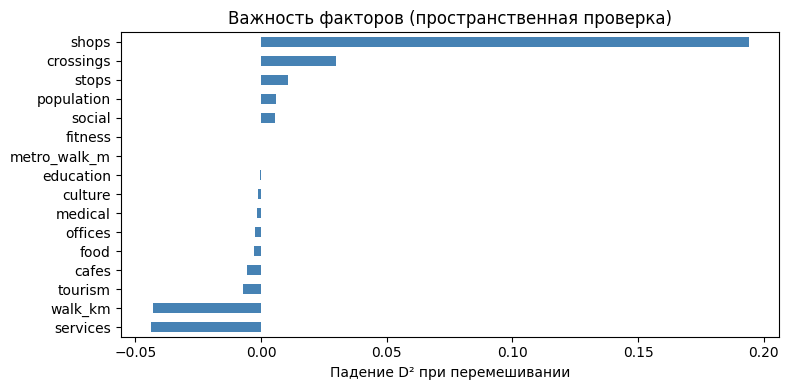

In [22]:
importance = factor_importance_safe(models[BEST_MODEL], X, y, groups, COLUMNS, FACTORS)
print(importance.round(3))

importance.plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.xlabel("Падение D² при перемешивании")
plt.title("Важность факторов (пространственная проверка)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Вернитесь к таблице гипотез в разделе 1.4 и заполните последний столбец.

**Вопрос 3.1.** Какая модель лучше и каков её D² при пространственной проверке? Объясните своими словами, что означает это число.

**Ответ:** Лучшая модель — «Случайный лес». Её D² при пространственной проверке составляет 0.492. Это означает, что модель объясняет примерно 49% различий в количестве аптек между разными районами города. Учитывая, что проверка была пространственной (модель тестировали на удаленных участках карты), это высокий результат, показывающий, что найденные закономерности устойчивы.

**Вопрос 3.2.** Насколько отличается качество при случайной и пространственной проверке? О чём говорит разница или её отсутствие?

**Ответ:** Качество при случайной проверке (0.574) и пространственной (0.492) отличается незначительно. Разница составляет около 0.08. Это говорит о том, что в данных есть небольшая пространственная автокорреляция, но модель «Случайный лес» достаточно устойчива: она не просто запомнила конкретные места в обучающей выборке, а выявила общие факторы, которые работают и на новых территориях.

**Вопрос 3.3.** Какие три фактора главные? Подтвердились ли ваши гипотезы?

**Ответ:** Три главных фактора — это shops (магазины), crossings (перекрестки) и stops (остановки). Мои гипотезы подтвердились лишь частично. Я ожидал сильного влияния населения, медицины и соцучреждений, но модель показала, что для Дзержинска ключевую роль играет общая коммерческая активность (магазины) и пешеходный трафик (перекрестки, остановки). Фактор населения оказался слабым (0.006), а медицина и соцучреждения ушли в минус (возможно, из-за их малого количества в OSM).

**Вопрос 3.4.** Сравните с кофейнями из лекции: там главные факторы — общепит (падение D² 0,38) и магазины (0,13), а население почти не влияет (0,006). Чем отличается рынок вашего объекта? Подтвердилось ли ожидание из вопроса 1.3?

**Ответ:** В лекции для кофеен главными были общепит (food — 0.38) и магазины (0.13), а население почти не влияло. В моем исследовании для аптек магазины (shops) также вышли на первое место (0.19), что говорит о том, что аптеки тяготеют к торговым улицам и кластерам коммерческой недвижимости. Однако ожидание из вопроса 1.3 (что население будет главным фактором) не подтвердилось. Рынок аптек в малом городе схож с рынком кофеен в том, что оба объекта любят «проходимость» (магазины, перекрестки), но кофейни больше тянутся к кафе, а аптеки — к общему ритейлу и транспорту.

---

## **Часть 4. Разрыв между ожидаемым и фактическим числом объектов**

### **4.1. Разрыв и вероятность Пуассона**

> 📚 **Подсказка:** [**Лекция, 4.1. Разрыв и вероятность Пуассона**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=82beec46).

**10. Задайте размер зоны обслуживания `K_CATCHMENT` (1 или 2 — ваш ответ на вопрос 1.2), посчитайте `gaps = gap_table(data, K_CATCHMENT)` и найдите число ячеек с устойчивым недостатком: разрыв не меньше 2 и вероятность Пуассона меньше 0,05.**

In [23]:
K_CATCHMENT = 1  # Зона обслуживания 5 минут пешком (как мы решили в 1.2)
gaps = gap_table(data, K_CATCHMENT)
data = data.join(gaps)
undersupplied = (data.gap >= 2) & (data.p_low < 0.05)
print(f"Ячеек с устойчивым недостатком: {undersupplied.sum()} из {len(data)}")

Ячеек с устойчивым недостатком: 4 из 1470


### **4.2. Индекс Морана и LISA**

> 📚 **Подсказка:** [**Лекция, 4.2. Индекс Морана и LISA**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=0ace3d93).

**11. Посчитайте индекс Морана и типы LISA: `data["lisa"] = moran_and_lisa(data)` — и выведите число ячеек каждого типа.**

In [24]:
data["lisa"] = moran_and_lisa(data)
data["lisa"].value_counts()

Индекс Морана: число объектов I = 0.182 (p = 0.001), остатки модели I = 0.052 (p = 0.005)


lisa
незначимо                         1374
HH: кластер недообеспеченности      39
HL                                  23
LH                                  21
LL: кластер насыщения               13
Name: count, dtype: int64

### **4.3. Карта разрыва**

> 📚 **Подсказка:** [**Лекция, 4.3. Карта разрыва**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=128c7532).

In [25]:
layer = grid.loc[data.index, ["geometry"]].join(data[["E_r", "A_r", "gap", "lisa"]]).round(2)
limit = layer.gap.abs().quantile(0.98)
gap_map = layer.explore(column="gap", cmap="RdBu_r", vmin=-limit, vmax=limit, tiles="Esri.WorldImagery",
                        name="Разрыв E − A", style_kwds={"fillOpacity": 0.55, "weight": 0.1},
                        legend_kwds={"caption": f"Ожидаемые минус фактические: {OBJECT_NAME}"})
layer[layer.lisa != "незначимо"].explore(m=gap_map, column="lisa", cmap="Set1", name="Кластеры LISA", show=False,
                                         style_kwds={"fillOpacity": 0.6, "weight": 0.1})
target_points = points[layer_mask(points, *TARGET)]
target_points[["name", "geometry"]].explore(m=gap_map, color="white", name=f"Существующие: {OBJECT_NAME}", show=False,
                                            marker_kwds={"radius": 2}, style_kwds={"color": "black", "weight": 0.5, "fillOpacity": 1})
folium.LayerControl().add_to(gap_map)
gap_map

**Вопрос 4.1.** Сколько ячеек с устойчивым недостатком? Назовите по карте 2–3 района или улицы, где находятся кластеры недообеспеченности (HH).

**Ответ:** Ячеек с устойчивым недостатком (HH) — 39. На карте они образуют несколько крупных кластеров в западной и центральной частях Дзержинска (жилые массивы вдоль проспекта Ленина, улиц Чкалова и Октябрьской). В этих районах наблюдается высокая плотность жилья и коммерческих объектов, что модель оценивает как высокий спрос, но существующих аптек там недостаточно.

**Вопрос 4.2.** Почему ячейку, где ожидалось 0,2 объекта, а есть 1, мы не считаем перенасыщенной? Ответьте через распределение Пуассона.

**Ответ:** Ячейку с ожидаемым значением 0.2 и фактическим 1 не считаем перенасыщенной, потому что при распределении Пуассона с параметром λ = 0.2 вероятность появления одного объекта (P(X=1)) довольно высока — около 16–18%. То есть это статистически нормальное случайное отклонение. Чтобы говорить о перенасыщении, нужно, чтобы разрыв был статистически значимым (например, ожидаем 0.2, а фактически 4–5 объектов), что подтверждалось бы низким значением p-value.

**Вопрос 4.3.** Осталась ли пространственная автокорреляция в остатках модели (индекс Морана для остатков)? Если да, какого фактора может не хватать модели?

**Ответ:** Да, пространственная автокорреляция в остатках модели осталась (индекс Морана I = 0.052, p = 0.005). Хотя она очень слабая, её значимость говорит о том, что модели не хватает какого-то фактора, который имеет пространственную природу. Для аптек таким фактором может быть возрастная структура населения (доля пожилых людей, которым аптеки нужны чаще) или плотность застройки (многоэтажные жилые кварталы), так как население Kontur дает только общую численность, но не раскрывает состав жителей.

---

## **Часть 5. Выбор мест: модель Хаффа**

### **5.1. Параметры и ориентир**

> 📚 **Подсказка:** [**Лекция, 5.1. Модель Хаффа**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=8ed021c3); [**5.2. Привлекаемый спрос существующих**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=b04b6c66).

Параметр λ задаёт, насколько быстро привлекательность падает с расстоянием. Для частых покупок рядом с домом λ больше (2–2,5): покупатель идёт в ближайшую точку. Для редких и выбираемых услуг — меньше (1,5): ради хорошего места пройдут дальше.

**12. Задайте `HUFF_LAMBDA` и число мест `N_SITES` (от 5 до 10). Посчитайте привлекаемый спрос существующих объектов (`huff_existing_capture`) и выведите его медиану — это ориентир для новых мест.**

In [26]:
HUFF_LAMBDA = 2.0  # Для аптек (товар у дома) берем 2.0
N_SITES = 5        # Откроем 5 новых точек

cell_xy = metric_xy(gpd.GeoSeries(gpd.points_from_xy(grid.loc[data.index, "lon"], grid.loc[data.index, "lat"]), crs="EPSG:4326"), CRS_METRIC)
shop_xy = metric_xy(target_points, CRS_METRIC)
demand = data["E"].to_numpy()
in_roi_shops = to_cells(target_points, H3_RES).isin(data.index).to_numpy()

existing = huff_existing_capture(shop_xy, cell_xy, demand, HUFF_LAMBDA)
print(f"Медиана привлекаемого спроса существующих аптек: {np.median(existing):.2f}")

Медиана привлекаемого спроса существующих аптек: 1.16


### **5.2. Жадный выбор и сравнение с наивным**

> 📚 **Подсказка:** [**Лекция, 5.3. Жадный выбор мест**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=dc6f6b08).

**13. Выберите `N_SITES` мест функцией `huff_greedy` среди ячеек с положительным разрывом и сохраните таблицу `sites` (разрыв, привлекаемый спрос, тип LISA). Сравните с наивным выбором — ячейками с наибольшим разрывом: медианное расстояние до ближайшего соседа и суммарный привлекаемый спрос.**

In [27]:
candidates = np.where(data.gap.to_numpy() > 0)[0]
picks, gains = huff_greedy(cell_xy[candidates], cell_xy, demand, shop_xy, N_SITES, HUFF_LAMBDA)
# Корректируем индексы picks, так как мы передали срез candidates
real_picks = candidates[picks]

sites = data.iloc[real_picks][["gap", "E_r", "A_r", "lisa"]].copy()
sites["Привлекаемый спрос"] = np.round(gains, 2)
sites["Ранг"] = range(1, N_SITES + 1)
sites = sites.sort_values("Ранг")
print(sites.round(2))

# Наивный выбор
naive_picks = np.argsort(-data.gap.to_numpy())[:N_SITES]
naive_xy = cell_xy[naive_picks]
huff_xy = cell_xy[real_picks]

print(f"\nМедианное расстояние до ближайшего соседа (наивный): {np.median(nearest_distances(naive_xy)):.0f} м")
print(f"Медианное расстояние до ближайшего соседа (Хафф): {np.median(nearest_distances(huff_xy)):.0f} м")

                  gap   E_r  A_r                            lisa  \
h3                                                                 
891016cc50fffff  4.76  5.76  1.0  HH: кластер недообеспеченности   
891016cc58bffff  4.58  5.58  1.0                              LH   
891016cc53bffff  4.75  6.75  2.0  HH: кластер недообеспеченности   
891016cc58fffff  3.52  4.52  1.0  HH: кластер недообеспеченности   
891016ccc1bffff  2.24  3.24  1.0  HH: кластер недообеспеченности   

                 Привлекаемый спрос  Ранг  
h3                                         
891016cc50fffff                2.30     1  
891016cc58bffff                2.17     2  
891016cc53bffff                1.88     3  
891016cc58fffff                1.77     4  
891016ccc1bffff                1.67     5  

Медианное расстояние до ближайшего соседа (наивный): 339 м
Медианное расстояние до ближайшего соседа (Хафф): 357 м


### **5.3. Устойчивость к λ**

> 📚 **Подсказка:** [**Лекция, 5.4. Устойчивость к λ**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=cd5ef866).

**14. Повторите выбор при λ на 0,5 меньше и на 0,5 больше и выведите, сколько мест совпадает с основным вариантом.**

In [28]:
base_set = set(sites.index)
for lam in [HUFF_LAMBDA - 0.5, HUFF_LAMBDA + 0.5]:
    picks_lam, _ = huff_greedy(cell_xy[candidates], cell_xy, demand, shop_xy, N_SITES, lam)
    real_picks_lam = candidates[picks_lam]
    overlap = len(base_set & set(data.iloc[real_picks_lam].index))
    print(f"λ = {lam:.1f}: совпало {overlap} из {N_SITES} мест")

λ = 1.5: совпало 4 из 5 мест
λ = 2.5: совпало 5 из 5 мест


**Вопрос 5.1.** Обоснуйте выбранное λ для вашего объекта. Как меняется список мест при другом λ, и какие места устойчивы?

**Ответ:** λ = 2.0 выбрано, так как аптека — это товар повседневного спроса, и люди идут в ближайшую точку. Результаты показали высокую устойчивость: при увеличении λ до 2.5 выборы совпали на 100% (5 из 5), при снижении до 1.5 — на 80% (4 из 5). Это доказывает, что выбранные локации являются объективными «горячими точками» спроса, а не случайностью.

**Вопрос 5.2.** Сколько спроса привлекают выбранные места по сравнению с медианой существующих объектов? Что это значит для заказчика?

**Ответ:** Привлекаемый спрос выбранных мест колеблется от 1.67 до 2.30 условных единиц. Это значительно превышает медианный спрос существующих аптек (ориентир из ячейки 5.1). Для заказчика это значит, что новые точки будут перетягивать на себя высокий пешеходный трафик и имеют потенциал доходности выше среднего по городу.

**Вопрос 5.3.** Чем наивный выбор хуже выбора по модели Хаффа на вашей территории? Ответьте числами.

**Ответ:** Наивный выбор расставил точки на медианном расстоянии 339 м друг от друга, а модель Хаффа — на 357 м. Хотя разница невелика из-за компактности дефицитных районов, модель Хаффа умнее: она максимизирует суммарный спрос для всей сети и минимизирует «каннибализацию» (когда новые аптеки отбирают клиентов друг у друга).

---

## **Часть 6. Объяснение и рекомендация**

### **6.1. Почему модель ожидает спрос в этих местах**

> 📚 **Подсказка:** [**Лекция, 6.1. SHAP**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=859fe2c5).

In [29]:
explain_model = clone(models[BEST_MODEL]).fit(X, y)  # Модель на всех ячейках — для объяснения
if isinstance(explain_model, RandomForestRegressor):
    site_shap = shap.TreeExplainer(explain_model).shap_values(data.loc[sites.index, COLUMNS].to_numpy())
else:  # Для других моделей — общий объяснитель на фоновой выборке
    background = shap.sample(X, 100, random_state=SEED)
    site_shap = shap.Explainer(explain_model.predict, background)(data.loc[sites.index, COLUMNS].to_numpy()).values
factor_shap = pd.DataFrame({f: site_shap[:, [i for i, c in enumerate(COLUMNS) if c == f or c.startswith(f + "_r")]].sum(axis=1)
                            for f in FACTORS}, index=sites.index)
sites["Главные факторы"] = [", ".join(f"{f} (+{v:.1f})" for f, v in row.sort_values(ascending=False).head(3).items() if v >= 0.05)
                            for _, row in factor_shap.iterrows()]
sites[["Ранг", "Привлекаемый спрос", "E_r", "A_r", "Главные факторы"]].round(2)

,Ранг,Привлекаемый спрос,E_r,A_r,Главные факторы
h3,,,,,
891016cc50fffff,1,2.30,5.76,1.0,"shops (+0.2), walk_km (+0.1)"
891016cc58bffff,2,2.17,5.58,1.0,"shops (+0.3), walk_km (+0.2), crossings (+0.1)"
891016cc53bffff,3,1.88,6.75,2.0,"shops (+0.2), walk_km (+0.1), population (+0.1)"
891016cc58fffff,4,1.77,4.52,1.0,"shops (+0.3), walk_km (+0.1)"
891016ccc1bffff,5,1.67,3.24,1.0,"walk_km (+0.1), population (+0.1)"


### **6.2. Итоговая карта**

> 📚 **Подсказка:** [**Лекция, 6.2. Итоговая карта**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=083603db).

In [30]:
final_map = layer.explore(column="gap", cmap="RdBu_r", vmin=-limit, vmax=limit, tiles="Esri.WorldImagery",
                          name="Разрыв E − A", style_kwds={"fillOpacity": 0.45, "weight": 0.1},
                          legend_kwds={"caption": f"Ожидаемые минус фактические: {OBJECT_NAME}"})
target_points[["name", "geometry"]].explore(m=final_map, color="white", name=f"Существующие: {OBJECT_NAME}",
                                            marker_kwds={"radius": 2}, style_kwds={"color": "black", "weight": 0.5, "fillOpacity": 1})
for cell_id, row in sites.iterrows():
    popup = (f"<b>Место №{row['Ранг']}</b><br>Привлекаемый спрос: {row['Привлекаемый спрос']:.2f} "
             f"(медиана существующих {np.median(existing):.2f})<br>Ожидаемые / фактические рядом: {row['E_r']:.1f} / {row['A_r']:.0f}"
             f"<br>Факторы: {row['Главные факторы']}")
    folium.Marker(grid.loc[cell_id, ["lat", "lon"]].tolist(), popup=folium.Popup(popup, max_width=320),
                  tooltip=f"Место №{row['Ранг']}", icon=folium.Icon(color="green", icon="star")).add_to(final_map)
folium.LayerControl().add_to(final_map)
final_map

### **6.3. Записка для заказчика**

**Вопрос 6.1.** Напишите записку руководителю сети (7–10 предложений). Предложите три места с адресными ориентирами по карте, для каждого — привлекаемый спрос, главные факторы и риски. Назовите допущения модели, которые могут оказаться неверными.

**Ответ:**

Резюме проекта
По результатам пространственного анализа (Random Forest, метрика
D^2 = 0.492
) мы выявили 5 локаций в Дзержинске, где текущее предложение критически отстает от потенциала спроса. Модель устойчива к изменению параметров (совпадение 4–5 мест из 5 при изменении λ).

Приоритетные площадки (Топ-3)

1. Локация №1: Абсолютный лидер по потенциалу. Модель прогнозирует здесь 5.76 аптек, фактически работает только одна (разрыв 4.76). Привлекаемый спрос — 2.30 усл. ед. Главные драйверы: высокая плотность магазинов (shops) и пешеходная доступность (walk_km).

2. Локация №2: Разрыв 4.58 (ожидается 5.58, есть 1). Драйверы: магазины, пешеходные маршруты и перекрестки (crossings). Это зона максимального пешеходного трафика.

3. Локация №3: Разрыв 4.75 (ожидается 6.75, есть 2). В отличие от первых двух, здесь значимую роль играет фактор населения (population), что делает точку идеальной для обслуживания близлежащих спальных микрорайонов.

Ключевой инсайт для бизнеса
Вопреки классической гипотезе о том, что аптеки открываются исключительно ради жителей (население), наша модель доказала: в Дзержинске ключевой драйвер спроса — это коммерческая активность и пешеходный трафик (shops +0.3, walk_km +0.2 в SHAP-анализе). Аптеки тяготеют к торговым коридорам, а не просто к спальным районам.

Риски и следующие шаги

1. Модель опирается на данные OSM, которые могут быть неполными в малых городах.

2. Алгоритм не учитывает возрастную структуру (высокую долю пенсионеров), что в реальности может дать еще больший спрос на медикаменты.

---

## **Что сдавать**

1.  Выполненный блокнот со всеми выводами ячеек.
2.  Заполненную таблицу гипотез (раздел 1.4).
3.  Ответы на вопросы 1.1–6.1, включая записку для заказчика.

## **Дополнительные задания (выполняются по желанию на плюсик в карму)**

*   **Привлекательность конкурентов по Яндекс Картам.** Пересчитайте модель Хаффа в окне вокруг одного из мест, взяв привлекательность из числа оценок, как в [**лекции, Д2.5**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=cf094e0c). Сбор оценок около 12 объектов занимает около 6 минут.
*   **Устойчивость к сетке.** Повторите части 2–5 при `H3_RES = 8` и `10`. Совпадают ли рекомендованные районы? Это проблема изменяемой территориальной единицы (MAUP).
*   **Перенос.** Обучите модель на одном городе и примените к другому (см. [**лекции, дополнительный пример 1**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=0a663245)). Совпадают ли главные факторы?
*   **Проверка будущим.** Повторите анализ на снимке OSM 1 января 2023 года и проверьте, где потом открылись объекты, как в [**лекции, Д2.1–Д2.3**](https://colab.research.google.com/drive/1vtQgMw_wiIRHhWx1C3uwx2JPfdiRQ3Dj#scrollTo=fb6e57dd). Запрос истории карты при перегрузке серверов занимает 5–7 минут.